# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

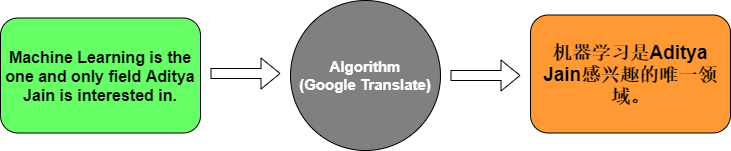

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1429 - loss: 2.4864

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1429 - loss: 2.4864 - val_accuracy: 0.0000e+00 - val_loss: 2.4873


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.1429 - loss: 2.4779

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.1429 - loss: 2.4779 - val_accuracy: 0.0000e+00 - val_loss: 2.4896


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.8571 - loss: 0.5573 - val_accuracy: 0.0000e+00 - val_loss: 5.7029


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7143 - loss: 1.7855

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.7143 - loss: 1.7855


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 517ms/step


Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

1. **Embedding:** It turns a word index (just an ID number) into a dense vector of learned values, so words with similar meanings end up with similar vectors.
2. **Encoder LSTM:** It reads the English sentence word by word and compresses it into a fixed-size vector (its final hidden state) that summarizes the meaning of the whole sentence.
3. **Decoder LSTM:** It takes that summary vector (repeated once per output position) and produces a hidden state for each position of the French sentence, which is then used to pick the French word.
4. **Softmax:** It converts the raw scores for every word in the French vocabulary into probabilities that sum to 1, so the model can pick the most likely word at each position and be trained with cross-entropy loss.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Approach:** The toy model above repeats the encoder output and predicts all French words at once. For real data we use an encoder-decoder (seq2seq) LSTM with **teacher forcing**: the decoder gets the previous correct French word as input and predicts the next one. At inference time it feeds back its own predictions, one word at a time.

In [8]:
import re
import pandas as pd
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model

df = pd.read_csv("content/eng_-french.csv")
df.columns = ["english", "french"]
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [9]:
def clean(text):
    text = text.lower().replace("\u2019", "'")
    text = re.sub(r"[^\w\s']", " ", text)  # keep letters (including accents) and apostrophes
    return re.sub(r"\s+", " ", text).strip()

df["english"] = df["english"].apply(clean)
df["french"] = df["french"].apply(clean)
df = df.drop_duplicates()

# Keep short sentences and a random sample so training is fast on a CPU
MAX_LEN = 8
NUM_SAMPLES = 25000
short = df[(df["english"].str.split().str.len() <= MAX_LEN) & (df["french"].str.split().str.len() <= MAX_LEN)]
data = short.sample(n=NUM_SAMPLES, random_state=42).reset_index(drop=True)

# Start and end tokens tell the decoder where a sentence begins and ends
data["french"] = "startseq " + data["french"] + " endseq"
data.head()

,english,french
0,day will break soon,startseq le jour se lèvera sous peu endseq
1,are you through with the newspaper,startseq en as tu terminé avec le journal endseq
2,you said it wasn't going to happen,startseq tu as dit que ça n'allait pas arriver...
3,you aren't like the others,startseq vous n'êtes pas comme les autres endseq
4,it's annoying,startseq c'est agaçant endseq


In [10]:
tokenizer_eng = Tokenizer(filters="")
tokenizer_eng.fit_on_texts(data["english"])
tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(data["french"])

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1
print(f"English vocab: {eng_vocab}, French vocab: {frn_vocab}")

# Pre-padding for the encoder so its final state comes right after the real words
eng_seq = pad_sequences(tokenizer_eng.texts_to_sequences(data["english"]), maxlen=MAX_LEN)
frn_seq = pad_sequences(tokenizer_frn.texts_to_sequences(data["french"]), maxlen=MAX_LEN + 2, padding="post")

eng_train, eng_test, frn_train, frn_test = train_test_split(eng_seq, frn_seq, test_size=0.1, random_state=42)

# Decoder input is the French sentence, target is the same sentence shifted by one word
dec_in_train, dec_out_train = frn_train[:, :-1], frn_train[:, 1:]
print(eng_train.shape, dec_in_train.shape, dec_out_train.shape)

English vocab: 6440, French vocab: 10649


(22500, 8) (22500, 9) (22500, 9)


In [11]:
LATENT = 256

# Encoder
enc_inputs = Input(shape=(None,))
enc_emb = Embedding(eng_vocab, 128)(enc_inputs)
_, state_h, state_c = LSTM(LATENT, return_state=True)(enc_emb)

# Decoder, initialized with the encoder states
dec_inputs = Input(shape=(None,))
dec_embedding = Embedding(frn_vocab, 128)
dec_lstm = LSTM(LATENT, return_sequences=True, return_state=True)
dec_dense = Dense(frn_vocab, activation="softmax")
dec_outputs, _, _ = dec_lstm(dec_embedding(dec_inputs), initial_state=[state_h, state_c])
outputs = dec_dense(dec_outputs)

seq2seq = Model([enc_inputs, dec_inputs], outputs)
seq2seq.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
seq2seq.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 128) │    824,320 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 128) │  1,363,072 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 256),     │    394,240 │ embedding_1[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, None,     │    394,240 │ embedding_2[0][0… │
│                     │ 256), (None,      │            │ lstm_2[0][1],     │
│                     │ 256), (None,      │            │ lstm_2[0][2]      │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │  2,736,793 │ lstm_3[0][0]      │
│                     │ 10649)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,712,665 (21.79 MB)

 Trainable params: 5,712,665 (21.79 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Weight 0 on padding positions so the model is not rewarded for predicting padding
weights = (dec_out_train != 0).astype("float32")

history = seq2seq.fit([eng_train, dec_in_train], dec_out_train, sample_weight=weights,
                      epochs=10, batch_size=128, validation_split=0.1, verbose=2,
                      callbacks=[tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])

Epoch 1/10


159/159 - 33s - 207ms/step - accuracy: 0.1279 - loss: 4.4663 - val_accuracy: 0.1471 - val_loss: 4.0416


Epoch 2/10


159/159 - 28s - 176ms/step - accuracy: 0.1547 - loss: 3.8362 - val_accuracy: 0.1617 - val_loss: 3.8468


Epoch 3/10


159/159 - 28s - 174ms/step - accuracy: 0.1726 - loss: 3.6009 - val_accuracy: 0.1810 - val_loss: 3.6772


... (10 outputs left out)

Epoch 9/10


159/159 - 28s - 176ms/step - accuracy: 0.2636 - loss: 2.6371 - val_accuracy: 0.2524 - val_loss: 3.0638


Epoch 10/10


159/159 - 29s - 183ms/step - accuracy: 0.2739 - loss: 2.5139 - val_accuracy: 0.2612 - val_loss: 2.9861


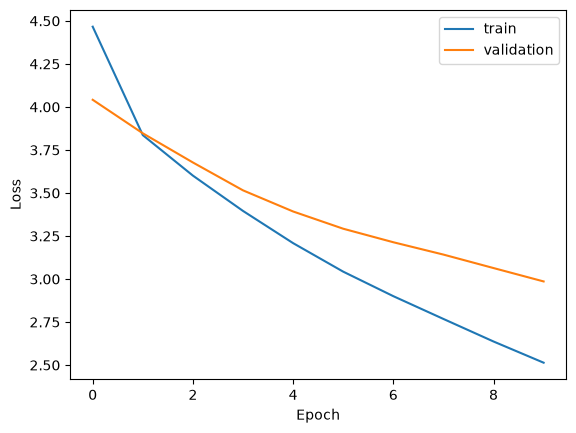

In [13]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [14]:
# Inference models: encoder gives the states, decoder predicts one word at a time
encoder_model = Model(enc_inputs, [state_h, state_c])

in_h, in_c = Input(shape=(LATENT,)), Input(shape=(LATENT,))
d_out, d_h, d_c = dec_lstm(dec_embedding(dec_inputs), initial_state=[in_h, in_c])
decoder_model = Model([dec_inputs, in_h, in_c], [dec_dense(d_out), d_h, d_c])

start_id = tokenizer_frn.word_index["startseq"]
end_id = tokenizer_frn.word_index["endseq"]

def translate(sentences):
    seq = pad_sequences(tokenizer_eng.texts_to_sequences([clean(s) for s in sentences]), maxlen=MAX_LEN)
    h, c = encoder_model.predict(seq, verbose=0)
    token = np.full((len(sentences), 1), start_id)
    preds = []
    for _ in range(MAX_LEN + 1):
        probs, h, c = decoder_model.predict([token, h, c], verbose=0)
        token = np.argmax(probs[:, -1], axis=-1)[:, None]  # greedy: pick the most likely word
        preds.append(token[:, 0])

    results = []
    for row in np.stack(preds, axis=1):
        words = []
        for idx in row:
            if idx in (end_id, 0):
                break
            words.append(tokenizer_frn.index_word[idx])
        results.append(" ".join(words))
    return results

In [15]:
# E-commerce style sentences
samples = [
    "This product is very good.",
    "I love this shirt.",
    "The price is too high.",
    "Where is my order?",
    "Thank you for your purchase.",
    "This book is very interesting.",
]
for s, t in zip(samples, translate(samples)):
    print(f"{s} -> {t}")

This product is very good. -> nous sommes très très
I love this shirt. -> je suis en train de moi
The price is too high. -> nous sommes tous les enfants
Where is my order? -> c'est un jour
Thank you for your purchase. -> où est ce que tu es de tom
This book is very interesting. -> ils ont été très très


In [16]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Compare with the reference translations on 1000 unseen test sentences
n = 1000
test_eng = tokenizer_eng.sequences_to_texts(eng_test[:n])
test_frn = tokenizer_frn.sequences_to_texts(frn_test[:n])
predictions = translate(test_eng)

references = [[[w for w in r.split() if w not in ("startseq", "endseq")]] for r in test_frn]
bleu = corpus_bleu(references, [p.split() for p in predictions], smoothing_function=SmoothingFunction().method1)
print(f"BLEU score: {bleu:.3f}\n")

for i in range(10):
    print(f"EN:   {test_eng[i]}")
    print(f"REF:  {' '.join(references[i][0])}")
    print(f"PRED: {predictions[i]}\n")

BLEU score: 0.018

EN:   do what you want with it
REF:  faites en ce que vous voulez
PRED: comment vous êtes vous

EN:   i feel like i'm going mad
REF:  j'ai l'impression de devenir folle
PRED: je veux que je suis en train de tom

EN:   when did the meeting start
REF:  quand la réunion a t elle commencé
PRED: le temps est un peu de temps

EN:   we never talked about that again
REF:  on n'a jamais reparlé de ça
PRED: il ne le monde a pas de tom

EN:   tom didn't want to continue the conversation
REF:  tom ne voulait pas poursuivre la conversation
PRED: tom ne peut pas faire ce que tom

EN:   please don't ask
REF:  ne demande pas je te prie
PRED: ne me suis pas de tom

EN:   you aren't looking
REF:  tu ne regardes pas
PRED: vous êtes pas de tom

EN:   why didn't you go to the police
REF:  pourquoi n'es tu pas allée voir la police
PRED: vous ne peux pas faire ce que tom

EN:   it nearly cost me my life
REF:  ça m'a presque coûté la vie
PRED: il a été de la maison à la maison

EN:   did i 

**Results:** After 10 epochs on 25k sentence pairs, validation loss is still dropping (4.04 to 2.99), but the BLEU score is only about 0.02. The model picks up common patterns (word order, "ne ... pas", "tom") but most translations are wrong.

**Why:** The training set is small, training is short (CPU only), and a basic LSTM squeezes the whole sentence into one vector. The dataset also has almost no shopping vocabulary.

**For the company:** To translate product listings and reviews in production, they would need to train on far more data (including e-commerce text) for longer, and use an attention or Transformer model, or fine-tune a pretrained model such as MarianMT (Helsinki-NLP/opus-mt-en-fr).